# Wilson–Cowan E–I field in 1D: weak forcing below onset

Two-population model from the PI's `wc2dn` code (`archive/legacy_code/wc2dn.py`). The notebook computes the onset and the amplitude coefficients of the paper (Secs. 1–6), then runs the full field below onset with each forcing type and compares the late amplitude with the standing equilibrium of the Proposition in Sec. 6.

All model logic is in `src/mcn_project/`. Change the parameters in the next cell.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from mcn_project import plotting, presets
from mcn_project.amplitude import standing_equilibrium
from mcn_project.analysis import critical_amplitudes, dominant_mode
from mcn_project.linear import find_onset
from mcn_project.normal_form import cubic_coefficients, unit_forcing_coefficients
from mcn_project.simulate import Forcing, Wave, critical_seed, simulate

plt.rcParams["figure.dpi"] = 80

In [2]:
# ---- parameters ----
MODEL = presets.wilson_cowan()   # edit numbers in src/mcn_project/presets.py
KAPPA_RANGE = (4.0, 9.0)         # kappa = a_EE
EPS, MU = 0.1, -1.0              # kappa = kappa_c + MU * EPS**2
PEAKS = dict(temporal=1.0, spatial=0.5, combined=(1.0, 0.03))  # cosine peaks, units of EPS**2; spatial threshold ~0.045
N, DT, T_END, SAVE_EVERY = 60, 0.1, 3000.0, 10
SEED, NOISE = 0.02, 1e-4         # initial critical-mode size and noise, units of EPS

## 1. Onset and amplitude coefficients

In [3]:
onset = find_onset(MODEL, dim=1, kappa_range=KAPPA_RANGE)
nf = cubic_coefficients(MODEL, onset)
eta_t1, eta_x1 = unit_forcing_coefficients(MODEL, onset)
print(f"kappa_c = {onset.kappa:.10f},  k0 = {onset.k0:g},  omega0 = {onset.omega0:.6f}")
print(f"alpha = {nf.alpha:.6f}\nb     = {nf.b:.6f}\nc     = {nf.c:.6f}")
print(f"eta_t^(1) = {eta_t1:.6f},  eta_x^(1) = {eta_x1:.6f}   (cosine peak 1 on drive {MODEL.drive})")
print(f"temporal threshold |mu alpha| / |eta_t^(1)| = {abs(MU * nf.alpha) / abs(eta_t1):.4f}")
print("unforced preference (Re c < Re b means traveling):", "traveling" if nf.c.real < nf.b.real else "standing")

kappa_c = 7.0249195280,  k0 = 3,  omega0 = 0.318128
alpha = 0.047165-0.048825j
b     = -0.715856-0.545818j
c     = -1.248695+4.101512j
eta_t^(1) = 0.287550+0.034009j,  eta_x^(1) = 1.049746+0.491768j   (cosine peak 1 on drive [1. 0.])
temporal threshold |mu alpha| / |eta_t^(1)| = 0.2344
unforced preference (Re c < Re b means traveling): traveling


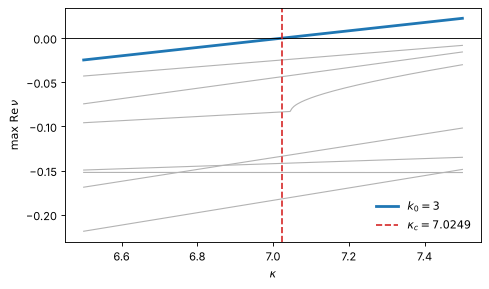

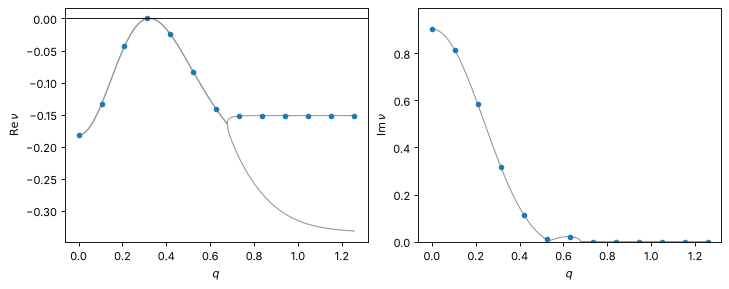

In [4]:
plotting.mode_growth(MODEL, np.linspace(6.5, 7.5, 201), range(8), onset);
plotting.dispersion(MODEL, onset.kappa, dim=1);

## 2. Forcing below onset

Temporal forcing at $2\omega_0$ and spatial forcing at $2k_0$ are the parametric resonances of Sec. 5. Detuned inputs have no leading-order projection, so the critical mode should decay. The spatial-only case has no standing equilibrium formula in Sec. 6 (it is `nan` below).

In [5]:
def run_case(name, waves, u0):
    return simulate(MODEL, onset.kappa + MU * EPS**2, Forcing(tuple(waves)), n=N, dt=DT,
                    t_end=T_END, save_every=SAVE_EVERY, u0=u0)

def prediction(dt=0.0, dx=0.0):
    """Standing equilibrium of Sec. 6 for cosine peaks dt, dx (units of EPS^2)."""
    eq = standing_equilibrium(MU * nf.alpha, nf.b, nf.c, dt * eta_t1, dx * eta_x1)
    return (np.nan, None) if eq is None else (EPS * np.sqrt(eq["rho"]), eq["stable"])

seed = critical_seed(MODEL, onset, SEED * EPS, n=N) + NOISE * EPS * np.random.default_rng(0).standard_normal((MODEL.K, N))
w0, k0 = onset.omega0, round(onset.k0)
cases = {
    "none": [],
    "temporal 2w0": [Wave(PEAKS["temporal"] * EPS**2, (), 2 * w0)],
    "spatial 2k0": [Wave(PEAKS["spatial"] * EPS**2, (2 * k0,))],
    "combined": [Wave(PEAKS["combined"][0] * EPS**2, (), 2 * w0), Wave(PEAKS["combined"][1] * EPS**2, (2 * k0,))],
    "detuned temporal 1.5w0": [Wave(PEAKS["temporal"] * EPS**2, (), 1.5 * w0)],
    "detuned spatial 3k0": [Wave(PEAKS["spatial"] * EPS**2, (3 * k0,))],
}
predicted = {"none": (0.0, None), "temporal 2w0": prediction(dt=PEAKS["temporal"]),
             "spatial 2k0": (np.nan, None), "combined": prediction(*PEAKS["combined"]),
             "detuned temporal 1.5w0": (0.0, None), "detuned spatial 3k0": (0.0, None)}
runs = {name: run_case(name, waves, seed) for name, waves in cases.items()}

In [6]:
print(f"{'case':24s} {'mean|A| late':>13s} {'mean|B| late':>13s} {'theory eps*sqrt(rho*)':>22s}  stable  mode")
for name, run in runs.items():
    A, B = critical_amplitudes(run, onset)
    late = run.t > 0.9 * run.t[-1]
    theory, stable = predicted[name]
    mode = dominant_mode(run.u[late, 0])
    print(f"{name:24s} {abs(A[late]).mean():13.3e} {abs(B[late]).mean():13.3e} {theory:22.3e}  {str(stable):6s}  {mode}")

case                      mean|A| late  mean|B| late  theory eps*sqrt(rho*)  stable  mode
none                         2.604e-04     9.608e-07              0.000e+00  None    (3,)
temporal 2w0                 2.331e-02     2.331e-02              2.345e-02  True    (3,)
spatial 2k0                  4.623e-02     4.623e-02                    nan  None    (3,)
combined                     2.355e-02     2.354e-02              2.358e-02  True    (3,)
detuned temporal 1.5w0       2.596e-04     5.784e-06              0.000e+00  None    (3,)
detuned spatial 3k0          2.640e-04     9.686e-07              0.000e+00  None    (9,)


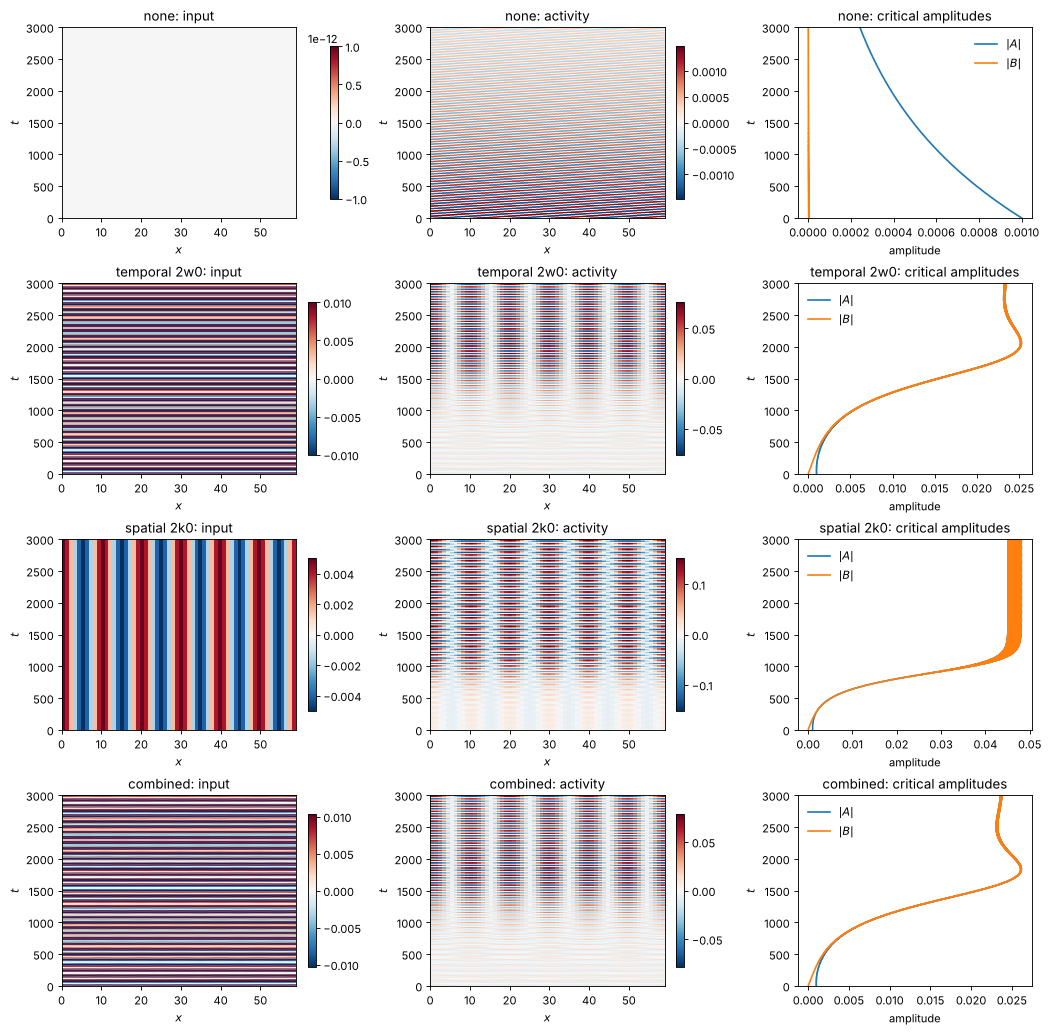

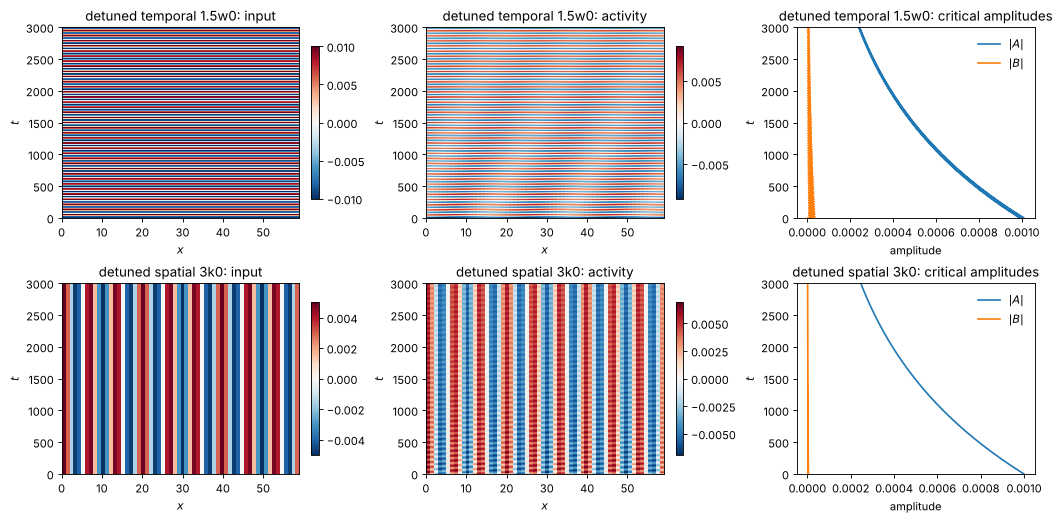

In [7]:
names = list(runs)
plotting.spacetime([runs[k] for k in names[:4]], names[:4], onset);
plotting.spacetime([runs[k] for k in names[4:]], names[4:], onset);